### MSE 401 — Homework 10 - Question 2: Thermodynamic Modeling of Benzene–Cyclohexane (11 points)

**Instructions**
- **[Task]** indicates work you should complete to obtain the deliverables.
- **[Graded]** identifies assessed calculations, plots or written responses that need to be submitted via Gradescope. You can directly take screenshots for your code outputs and discussions written in the notebook.

**Literature reference for the data:** Brown, C. P., Mathieson, A. R. and Thynne, J. C. J. (1955), *Journal of the Chemical Society*, 4141–4146. DOI: https://doi.org/10.1039/JR9550004141.


#### Thermodynamic model of the binary solution

In this question, we use the first-order Redlich–Kister model,

- Component 1: Benzene, $X_1$.
- Component 2: Cyclohexane, $X_2=1-X_1$. **In this question, all functions use $X_2$ as the independent variable**.

$$
\Delta H_{\mathrm{mix}}=X_1X_2(\alpha_1X_1+\alpha_2X_2).
$$

Assume $\alpha_1,\alpha_2$ are temperature-independent interaction parameters and $\Delta S_{\mathrm{mix}}^{XS}=0$. Thus,

$$
\Delta G_{\mathrm{mix}}^{\mathrm{XS}}=\Delta H_{\mathrm{mix}},\qquad
\Delta G_{\mathrm{mix}}^{\mathrm{id}}=RT(X_1\ln X_1+X_2\ln X_2),
$$

$$
\Delta G_{\mathrm{mix}}=\Delta G_{\mathrm{mix}}^{\mathrm{XS}}+\Delta G_{\mathrm{mix}}^{\mathrm{id}} = X_1X_2(\alpha_1X_1+\alpha_2X_2) + RT(X_1\ln X_1+X_2\ln X_2).
$$

Use $R=8.314462618\;\mathrm{J\,mol^{-1}\,K^{-1}}$ and $T_{\mathrm{ref}}=293.15\;\mathrm K$.

#### Setup: imports, data, and plotting tools.

In [12]:
# ============================================================================
# Imports and constants. Run this cell without modification.
# ============================================================================
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from matplotlib.ticker import AutoMinorLocator

R = 8.314462618                 # J/(mol K)
T_REF = 293.15                 # K
CSV_FILE = Path('HW10_Benzene_Cyclohexane_Data.csv')

# A fine composition grid helps resolve narrow 5% relative-error regions.
X2_GRID = np.linspace(0.0, 1.0, 2001)
X1_GRID = 1.0 - X2_GRID
# We use interior points for logarithms in part (b).
X2_INTERIOR = np.linspace(1e-4, 1 - 1e-4, 1001)

COLORS = {
    'data': '#4f647d',
    'model': '#256b85',
    'ideal': '#767676',
    'henry': '#bb6747',
    'gamma1': '#256b85',
    'gamma2': '#bb6747',
}

# ---------------------------------------------------------------------------
# Publication-style figure formatting — use for every question.
# You might use them for making your own plots.
# ---------------------------------------------------------------------------
from matplotlib.ticker import MultipleLocator, AutoMinorLocator
from cycler import cycler

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Tinos', 'Liberation Serif', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size': 12,
    'axes.labelsize': 13,
    'axes.labelweight': 'bold',
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.linewidth': 1.4,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.major.size': 6,
    'ytick.major.size': 6,
    'xtick.minor.size': 3,
    'ytick.minor.size': 3,
    'xtick.major.width': 1.1,
    'ytick.major.width': 1.1,
    'xtick.minor.width': 0.9,
    'ytick.minor.width': 0.9,
    'legend.frameon': False,
    'legend.fontsize': 10.5,
    'lines.linewidth': 2.2,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'axes.prop_cycle': cycler(color=[
        '#245E91', '#C17A36', '#6E8A69', '#A6535C', '#725CA4'
    ]),
})

def format_figure(fig, ax, xlabel, ylabel, title=None, legend=True,
                  save_name=None):
    """[Provided] Uniform journal-style formatting for all homework plots.

    Optional save_name='hw10_figure_a' saves 600-dpi PNG and vector PDF.
    All existing calls in this notebook work without modification.
    """
    ax.set_xlabel(xlabel, labelpad=7)
    ax.set_ylabel(ylabel, labelpad=8)
    if title:
        ax.set_title(title, pad=12)

    # The full four-sided frame used throughout our thermodynamics figures.
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.4)
        spine.set_color('black')
    ax.tick_params(axis='both', which='both', direction='in',
                   top=True, right=True, labelcolor='black')
    ax.xaxis.set_major_locator(MultipleLocator(0.2))
    ax.xaxis.set_minor_locator(MultipleLocator(0.05))
    ax.yaxis.set_minor_locator(AutoMinorLocator(2))
    ax.grid(False, which='both')
    ax.set_facecolor('white')

    if legend:
        handles, labels = ax.get_legend_handles_labels()
        if handles:
            ax.legend(loc='best', frameon=False, handlelength=2.5,
                      handletextpad=0.7)

    fig.set_facecolor('white')
    fig.tight_layout(pad=1.2)
    if save_name is not None:
        fig.savefig(f'{save_name}.png', dpi=600, bbox_inches='tight',
                    facecolor='white')
        fig.savefig(f'{save_name}.pdf', bbox_inches='tight',
                    facecolor='white')
    plt.show()


In [13]:
# ============================================================================
# Read the CSV and use X_2 as the composition variable.
# Keep the CSV beside this notebook. Do not edit this cell.
# ============================================================================
if not CSV_FILE.exists():
    raise FileNotFoundError(
        f'Cannot find {CSV_FILE.name}. Put the CSV in the same folder as this notebook.'
    )

experimental_data = pd.read_csv(CSV_FILE).sort_values('X_1').reset_index(drop=True)
required_columns = {'X_1', 'Delta_H_mix_J_per_mol'}
if not required_columns.issubset(experimental_data.columns):
    raise ValueError(f'CSV must contain these columns: {sorted(required_columns)}')

X1_DATA = experimental_data['X_1'].to_numpy(dtype=float)
X2_DATA = 1.0 - X1_DATA
H_DATA = experimental_data['Delta_H_mix_J_per_mol'].to_numpy(dtype=float)

print(f'Loaded {len(experimental_data)} data points at T = {T_REF:.2f} K')
display(experimental_data.head(6))

Loaded 22 data points at T = 293.15 K


,X_1,Delta_H_mix_J_per_mol
0,0.060,103
1,0.100,192
2,0.150,266
3,0.190,338
4,0.215,427
5,0.245,489


#### (a) [3 points] Experimental model fitting

Using the provided dataset of $\Delta H_{\mathrm{mix}}$, determine the interaction parameters $\alpha_1$ and $\alpha_2$ by least-squares fitting of $\Delta H_{\mathrm{mix}}$ against $X_2$. 

**[Task]** Complete the Redlich–Kister expression in `rk_enthalpy`. The least-squares fitting routine, $R^2$ evaluation, and figure code are provided. Use the CSV dataset to determine $\alpha_1$ and $\alpha_2$ and assess agreement between the model and the data.

$$\Delta H_{\mathrm{mix}}=X_1X_2(\alpha_1X_1+\alpha_2X_2).$$

In [14]:
# ============================================================================
# [Task] Redlich–Kister thermodynamic model .
# ============================================================================
def rk_enthalpy(x2, alpha1, alpha2):
    """Molar enthalpy of mixing (J/mol), using X_2 as independent variable."""
    x2 = np.asarray(x2, dtype=float)
    x1 = 1 - x2

    # [Task] Define the Redlich–Kister enthalpy of mixing expression.
    delta_H_mix = x1 * x2 * (alpha1 * x1 + alpha2 * x2)
    return delta_H_mix


**[Tutorial]** Least-squares fitting using `scipy.optimize.curve_fit`

`curve_fit` adjusts parameters in a model function until the squared differences between model predictions and data are as small as possible. The model must accept the independent variable first, followed by model parameters:

```python
def model(x, parameter_1, parameter_2):
    return ...

parameters, covariance = curve_fit(model, x_data, y_data,
                                   p0=(initial_1, initial_2))
```

For this question, `x_data` is $X_2$. The file provides $X_1$, so we first calculate $X_2=1-X_1$. Here `alpha1, alpha2 = parameters`. The coefficient of determination $R^2 is

$$R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}.$$

$R^2$ measures how well a fitted model explains the variation in the observed experimental data.

The data-loading, optimization, $R^2$ calculation and plotting code have already been provided. Only the thermodynamic model needs to be implemented.

**[Graded]** Plot the experimental data and the fitted curve in the same figure.

alpha_1 = 3914.103 J/mol
alpha_2 = 2388.727 J/mol
R² = 0.97017


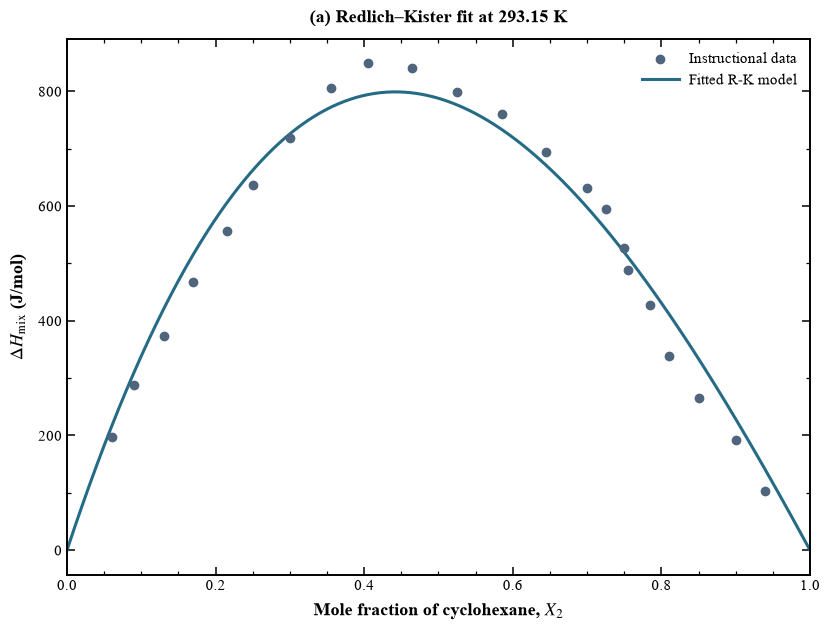

In [15]:
# ============================================================================
# [Graded] Part (a): least-squares fit, R², and figure.
# Run this cell after you complete the least square fitting below.
# ============================================================================
fit_parameters, fit_covariance = curve_fit(
  rk_enthalpy,X2_DATA ,H_DATA , p0=(3000.0, 3000.0), maxfev=10000 #Task: Complete the least-squares fitting.
)
alpha1, alpha2 = fit_parameters
H_FIT_DATA = rk_enthalpy(X2_DATA, alpha1, alpha2)

SSE = np.sum((H_DATA - H_FIT_DATA)**2)
SST = np.sum((H_DATA - np.mean(H_DATA))**2)
R_squared = 1.0 - SSE / SST

print(f'alpha_1 = {alpha1:.3f} J/mol')
print(f'alpha_2 = {alpha2:.3f} J/mol')
print(f'R² = {R_squared:.5f}')

x2_plot = np.linspace(0, 1, 501)
fig, ax = plt.subplots(figsize=(8.5, 6.5))
ax.scatter(X2_DATA, H_DATA, s=36, color=COLORS['data'],
           label='Instructional data', zorder=3)
ax.plot(x2_plot, rk_enthalpy(x2_plot, alpha1, alpha2),
        color=COLORS['model'], lw=2.2, label='Fitted R-K model')
ax.set_xlim(0, 1)
format_figure(fig, ax, r'Mole fraction of cyclohexane, $X_2$',
              r'$\Delta H_{\mathrm{mix}}$ (J/mol)',
              '(a) Redlich–Kister fit at 293.15 K')

**[Graded]** Report $\alpha_1$, $\alpha_2$ with units, as well as the coefficient of determination $R^2$. Briefly comment the fitting accuracy.



**You might complete your answer here by editing the markdown cell below and take the screenshot.**

#### (b) [3 points] Temperature dependence of $\Delta G_{mix}$

**[Task]** Implement the ideal and excess Gibbs-energy contributions in `gibbs_energy_of_mixing`. 

**[Tutorial]** Composition arrays, `np.log`, and numerical endpoints

Numpy operates **element by element** on an array. For example, `np.log(x2)` computes $\ln X_2$ at every composition. At a pure-component endpoint, $\ln 0$ is undefined in floating-point arithmetic, although the correct thermodynamic limit is

$$\lim_{x\to0^+}x\ln x=0.$$

Therefore, for the Gibbs-energy plot we use an **interior grid** such as: 
``np.linspace(1e-4, 1-1e-4, 1001)``

This avoids runtime warnings; it does not mean that the Gibbs energy of mixing diverges at the endpoints.

In [24]:
# ============================================================================
# [Graded] (b) Compute ideal and excess Gibbs energies.
# We deliberately use interior mole fractions to avoid log(0) in the plot.
# ============================================================================
def gibbs_energy_of_mixing(x2, T, alpha1, alpha2):
    """Molar Gibbs energy of mixing (J/mol) at X_2 and T."""
    x2 = np.asarray(x2, dtype=float)
    x1 = 1.0 - x2

    # [Task] Ideal solution mixing Gibbs free energy.
    G_ideal = R * T * (x1 * np.log(x1) + x2 * np.log(x2))

    # [Task] Excess mixing Gibbs free energy.
    G_excess = rk_enthalpy(x2, alpha1, alpha2)
    return G_ideal + G_excess


 **[Graded]** Using the fitted model, plot $\Delta G_{mix}$ as a function of $X_2$ at $T = 293.15 \,\mathrm{K}$, $303.15 \,\mathrm{K}, 313.15 \,\mathrm{K},$ $323.15\,\mathrm{K},$ and $333.15\,\mathrm{K}$ on the same figure.

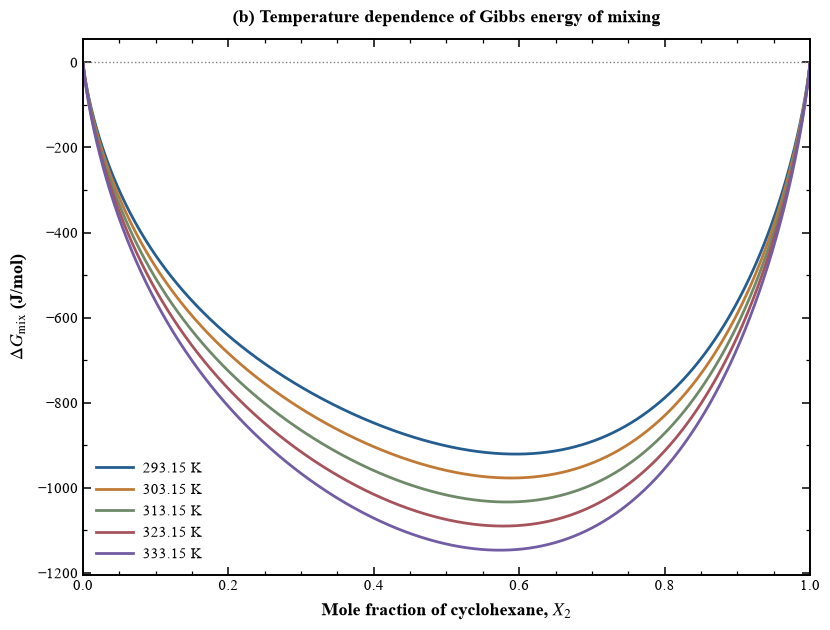

In [25]:
# ============================================================================
# [Graded] (b) Plot ΔG_mix at all five temperatures.
# ============================================================================
TEMPERATURES =   np.array([293.15, 303.15, 313.15, 323.15, 333.15])
fig, ax = plt.subplots(figsize=(8.5, 6.5))
for T in TEMPERATURES:
    G_values = gibbs_energy_of_mixing(X2_INTERIOR, T, alpha1, alpha2)
    ax.plot(X2_INTERIOR, G_values, lw=2, label=f'{T:.2f} K')
ax.axhline(0.0, ls=':', lw=1, color='gray')
ax.set_xlim(0, 1)
format_figure(fig, ax, r'Mole fraction of cyclohexane, $X_2$',
              r'$\Delta G_{\mathrm{mix}}$ (J/mol)',
              '(b) Temperature dependence of Gibbs energy of mixing')

**[Graded]** Explain whether mixing becomes more thermodynamically favorable as $T$ increases. Would this conclusion necessarily remain valid if the interaction parameters $\alpha_1$ and $\alpha_2$ were $T$ dependent? Support your answer with at least one relevant CALPHAD literature reference.

**You might complete your answer here by editing the markdown cell below and take the screenshot.**

#### (c) [2 points] Activity coefficient calculations and visualization

**[Tutorial]** Numerical Differentiation in Python: `scipy.differentiate.derivative`

The problem requires calculating $\dfrac{d\Delta G_{mix}^{XS}}{dX_2}$. You may derive this expression analytically using the product rule or use SciPy to calculate the derivative numerically.

Unlike symbolic differentiation, numerical differentiation evaluates the derivative at specified values of the independent variable without requiring an explicit analytical expression.

Example: For $f(x)=x^2(1-x)$, calculate $\dfrac{df}{dx}$ at several values of $x$ using `scipy.differentiate.derivative`.

In [26]:
# ============================================================================
# [Tutorial] Symbolic differentiation of a simple example using SymPy.
# This is a worked example, no changes are necessary.
# ============================================================================
from scipy.differentiate import derivative

# Define the function
def f(z):
    return z**2 * (1-z)

# Calculate the derivative at selected points
z = np.array([0.2, 0.5, 0.8])
f_prime = derivative(f, z).df

# Compare with the analytical derivative
f_prime_exact = z * (2 - 3*z)

print("z =", z)
print("Numerical derivative =", f_prime)
print("Analytical derivative =", f_prime_exact)

z = [0.2 0.5 0.8]
Numerical derivative = [ 0.28  0.25 -0.32]
Analytical derivative = [ 0.28  0.25 -0.32]


**[Task]** Now use `scipy.differentiate.derivative` to complete the derivative for the Redlich–Kister model below.

In [29]:
# ============================================================================
# [Task] Numerical differentiation of excess Gibbs energy using SciPy.
# ============================================================================

import numpy as np
from scipy.differentiate import derivative

# Define the excess Gibbs energy function
def Gex(X2):
    X1 = 1 - X2
    return X1 * X2 * (alpha1 * X1 + alpha2 * X2)

# Calculate the derivative at X2 = 0.4
X2_test = 0.4
dGex_dX2 = derivative(Gex, X2_test)
dGex_dX2_val = dGex_dX2.df

print('d(ΔG_mix^XS)/dX2 at X2 = 0.4:')
print(f'{dGex_dX2_val:.4f} J/mol')

# Optional: evaluate the derivative over the composition range
X2_grid = np.linspace(0.001, 0.999, 500)
dGex_numeric = derivative(Gex, X2_grid)


d(ΔG_mix^XS)/dX2 at X2 = 0.4:
294.7004 J/mol


Using the fitted Redlich-Kister model, determine the activity coefficients $\gamma_1$ and $\gamma_2$.

**[Task]** Fill the derivative and thermodynamic expressions in the two Python functions below, using $X_2$ as the independent variable.

You might find following relations helpful,

$$
\Delta\overline G_1^{XS}=\Delta G_{mix}^{XS}-X_2\frac{d\Delta G_{mix}^{XS}}{dX_2}
$$
$$
\Delta\overline G_2^{XS}=\Delta G_{mix}^{XS}+X_1\frac{d\Delta G_{mix}^{XS}}{dX_2}
$$

$$\gamma_k=\exp\left(\frac{\Delta\overline G_k^{XS}}{RT}\right),\quad k=1,2.$$


In [43]:
def excess_partial_molar_gibbs(x2, alpha1, alpha2):
    """Return (Gbar_1^XS, Gbar_2^XS), in J/mol."""
    x2 = np.asarray(x2, dtype=float)
    x1 = 1.0 - x2
    
    # Excess Gibbs energy from the fitted R-K model
    G_excess = rk_enthalpy(x2, alpha1, alpha2)
    
    # Define a helper function for G_excess to pass into derivative
    def g_ex(x):
        X1 = 1.0 - x
        return rk_enthalpy(x, alpha1, alpha2)
    
    # [Task] Calculate d(G_mix^XS)/dX2
    res = derivative(g_ex, x2)
    dGex_dx2 = res.df
    
    # [Task] Partial molar excess Gibbs energies
    Gbar1_excess = G_excess - x2 * dGex_dx2
    Gbar2_excess = G_excess + x1 * dGex_dx2
    
    return Gbar1_excess, Gbar2_excess

def activity_coefficients(x2, T, alpha1, alpha2):
    """Return (gamma_1, gamma_2), both dimensionless."""
    
    Gbar1_excess, Gbar2_excess = excess_partial_molar_gibbs(
        x2, alpha1, alpha2
    )
    
    # [Task] Calculate gamma_k
    gamma1 = np.exp(Gbar1_excess / (R * T))
    gamma2 = np.exp(Gbar2_excess / (R * T))
    
    return gamma1, gamma2



**[Graded]** Plot both $\gamma_1$ and $\gamma_2$ as functions of $X_2$ at $T = 293.15 \,\mathrm{K}$ on the same figure.

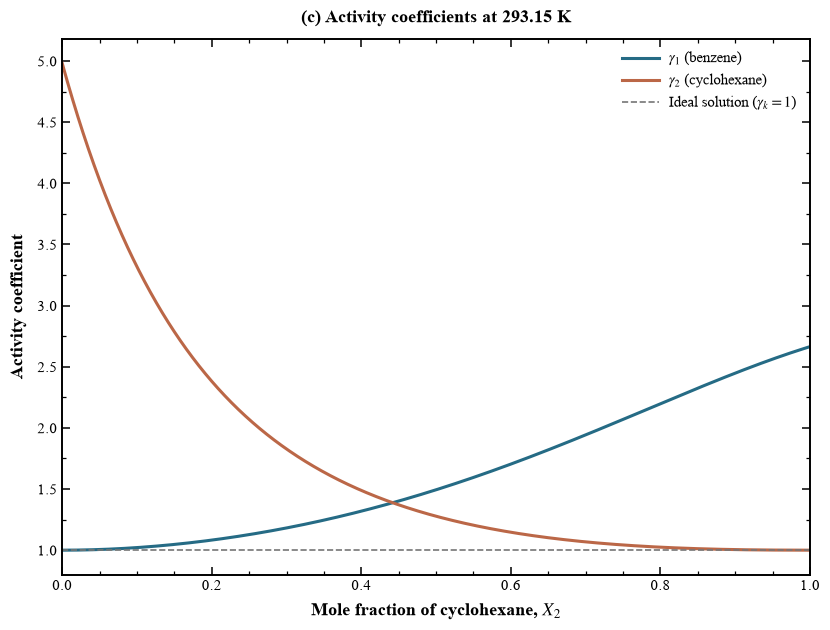

In [44]:
# ============================================================================
# [Provided] [Graded] (c) Plot both activity coefficients and report limits.
# ============================================================================
gamma1, gamma2 = activity_coefficients(X2_GRID, T_REF, alpha1, alpha2)

fig, ax = plt.subplots(figsize=(8.5, 6.5))
ax.plot(X2_GRID, gamma1, color=COLORS['gamma1'], lw=2.2,
        label=r'$\gamma_1$ (benzene)')
ax.plot(X2_GRID, gamma2, color=COLORS['gamma2'], lw=2.2,
        label=r'$\gamma_2$ (cyclohexane)')
ax.axhline(1.0, ls='--', lw=1.2, color=COLORS['ideal'],
           label=r'Ideal solution ($\gamma_k=1$)')
ax.set_xlim(0, 1)
format_figure(fig, ax, r'Mole fraction of cyclohexane, $X_2$',
              'Activity coefficient',
              '(c) Activity coefficients at 293.15 K')

#### (d) [3 points] Activities, Henry's law, and Raoult's law

Using the activity coefficients $\gamma_k$, calculate the activities $a_1$ and $a_2$, where 
$$
a_k = \gamma_k X_k \quad k = 1, 2
$$
At $T = 293.15 \,\mathrm{K}$, plot $a_1$ versus $X_1$ and $a_2$ versus $X_2$ in two separate figures. Include the limiting behaviors predicted by Henry's law and Raoult's law:
$$
a_k^{\mathrm{Henry}} = \gamma_k^0 X_k
$$
$$
a_k^{\mathrm{Raoult}} = X_k
$$

**[Task]** Write down the infinite-dilution coefficients:

With $X_1\to0$ (equivalently $X_2\to1$):

$$\gamma_1^0= \, ? .$$

With $X_2\to0$:

$$\gamma_2^0= \, ? .$$

At $293.15\ \mathrm K$, the positive interaction parameters give $\gamma_k>1$ at non-pure compositions, corresponding to positive deviations from Raoult's law. At the pure-component limits, $\gamma_1\to1$ as $X_1\to1$ and $\gamma_2\to1$ as $X_2\to1$.


In [45]:
# ============================================================================
# [Provided] Model sanity checks before proceeding to activities.
# These are physical/thermodynamic properties, not separate graded tasks.
# ============================================================================
# Pure-state activity coefficients should approach unity.
g1_pure = activity_coefficients(0.0, T_REF, alpha1, alpha2)[0]
g2_pure = activity_coefficients(1.0, T_REF, alpha1, alpha2)[1]
assert np.isclose(g1_pure, 1.0, atol=1e-12)
assert np.isclose(g2_pure, 1.0, atol=1e-12)
print('Pure-component check passed: gamma_1(X1=1) = gamma_2(X2=1) = 1')

Pure-component check passed: gamma_1(X1=1) = gamma_2(X2=1) = 1


In [48]:
# ============================================================================
# [Task] Model activities: a_k = gamma_k * X_k
# At infinite dilution, X_1 -> 0 means X_2 -> 1, and vice versa.
# ============================================================================

# [Task] Activity coefficients at infinite dilution.
gamma1_0 = activity_coefficients(1, T_REF, alpha1, alpha2)[0]
gamma2_0 = activity_coefficients(0, T_REF, alpha1, alpha2)[1]

# [Task] Activities from the fitted model.
a1 = gamma1 * X1_GRID
a2 = gamma2 * X2_GRID

# [Task] Henry's law with infinite-dilution coefficients from part (c).
a1_henry = gamma1_0 * X1_GRID
a2_henry = gamma2_0 * X2_GRID

# [Task] Raoult's law: a_k = X_k.
a1_raoult = X1_GRID
a2_raoult = X2_GRID


**[Graded]** Plot $a_1$ versus $X_1$ and $a_2$ versus $X_2$ in two separate figures. 

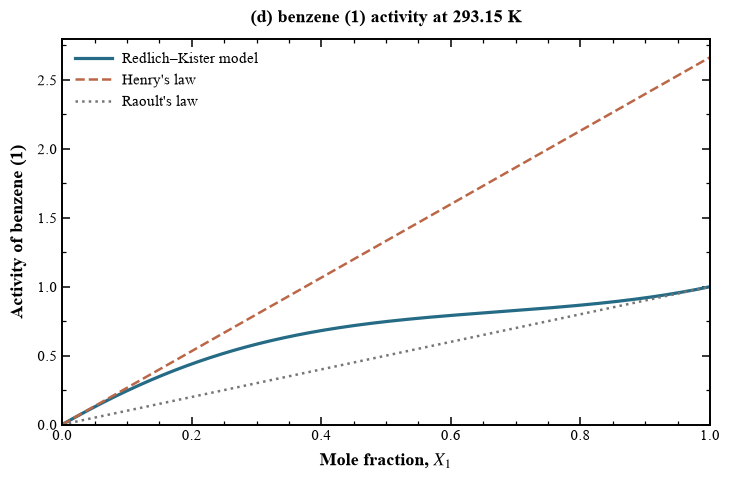

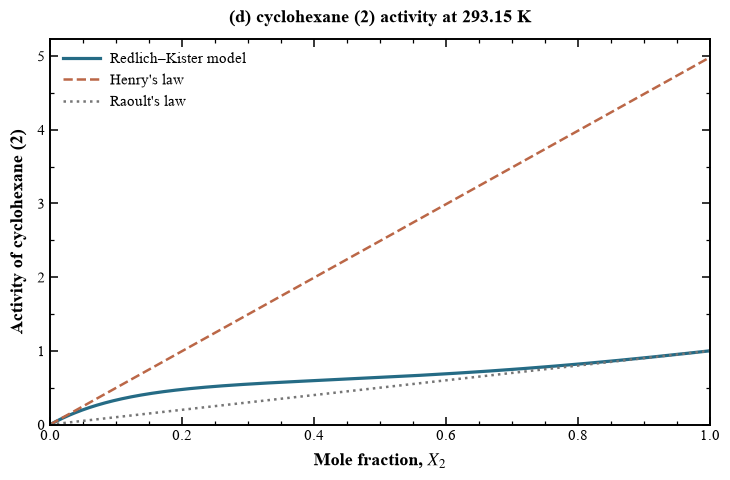

In [49]:
# ============================================================================
# [Provided] [Graded] (d) Two separate activity figures.
# ============================================================================

def plot_component_activity(x, activity, henry, raoult, component_label, x_symbol):
    order = np.argsort(x)  # ensures increasing mole fraction on the x-axis
    fig, ax = plt.subplots(figsize=(7.5, 5.0))
    ax.plot(x[order], activity[order], lw=2.3,
            color=COLORS['model'], label='Redlich–Kister model')
    ax.plot(x[order], henry[order], lw=1.8, ls='--',
            color=COLORS['henry'], label="Henry's law")
    ax.plot(x[order], raoult[order], lw=1.8, ls=':',
            color=COLORS['ideal'], label="Raoult's law")
    ax.set_xlim(0, 1)
    ax.set_ylim(bottom=0)
    format_figure(fig, ax, f'Mole fraction, ${x_symbol}$',
                  f'Activity of {component_label}',
                  f'(d) {component_label} activity at 293.15 K')

plot_component_activity(X1_GRID, a1, a1_henry, a1_raoult,
                        'benzene (1)', 'X_1')
plot_component_activity(X2_GRID, a2, a2_henry, a2_raoult,
                        'cyclohexane (2)', 'X_2')

**[Tutorial]** Relative-error masks and 5% composition intervals

For a model activity `a_model` and an approximation `a_approx`, the error in percent is

$$\mathrm{Error} = 100\% \times \left|\frac{a_{\mathrm{approx}}-a_{\mathrm{model}}}{a_{\mathrm{model}}}\right|.$$

Numpy evaluates this expression at each grid point. The comparison `error < 5` gives a **Boolean mask** indicating which points meet the criterion. The provided code groups consecutive valid grid points into composition intervals. Exclude $X_k=0$ (both activities vanish and relative error is undefined there).

Before executing the code, think about the following question:

In which composition regimes would you expect Henry's law and Raoult's law to provide the best approximations for each component?

**[Graded]** Identify the composition ranges where each limiting law provides a reasonable approximation under 5\% relative error.

In [50]:
# ============================================================================
# [Provided] [Graded] (d) Calculate where each approximation has <5% error.
# ============================================================================

def percent_relative_error(approx, actual):
    """Return 100*abs(approx - actual)/actual; undefined at actual=0."""
    approx = np.asarray(approx, dtype=float)
    actual = np.asarray(actual, dtype=float)
    result = np.full_like(actual, np.nan, dtype=float)
    np.divide(100.0 * np.abs(approx - actual), np.abs(actual),
              out=result, where=(np.abs(actual) > 1e-14))
    return result


def valid_intervals(x, error, threshold=5.0):
    """Find contiguous intervals on the supplied mole-fraction grid."""
    order = np.argsort(x)
    x_sorted = np.asarray(x)[order]
    e_sorted = np.asarray(error)[order]
    ok = np.isfinite(e_sorted) & (e_sorted < threshold)
    indices = np.flatnonzero(ok)
    if len(indices) == 0:
        return []
    boundaries = np.where(np.diff(indices) > 1)[0] + 1
    segments = np.split(indices, boundaries)
    return [(float(x_sorted[segment[0]]), float(x_sorted[segment[-1]]))
            for segment in segments]

for name, x, model, henry, raoult in (
    ('Benzene (1)', X1_GRID, a1, a1_henry, a1_raoult),
    ('Cyclohexane (2)', X2_GRID, a2, a2_henry, a2_raoult),
):
    print(f'\n{name}: <5% relative-error composition intervals')
    for law_name, approx in (('Henry', henry), ('Raoult', raoult)):
        intervals = valid_intervals(x, percent_relative_error(approx, model))
        if not intervals:
            print(f'  {law_name}: no grid points within threshold')
        else:
            formatted = ', '.join(f'{lo:.4f} – {hi:.4f}' for lo, hi in intervals)
            print(f'  {law_name}: {formatted}')


Benzene (1): <5% relative-error composition intervals
  Henry: 0.0005 – 0.0610
  Raoult: 0.8415 – 1.0000

Cyclohexane (2): <5% relative-error composition intervals
  Henry: 0.0005 – 0.0110
  Raoult: 0.7285 – 1.0000


**[Graded]** (d) Discuss the deviations from the ideal solution behavior.

**You might complete your answer here by editing the markdown cell below and take the screenshot.**

**Make sure to submit all Python outputs and your discussions marked as [Graded].**

In [55]:
#calculation of the energy of bond AB for question 4
T = 725
HA= 88200
HB = 134000
XB = 0.380
XA = 1 - XB
z = 6
Na = 6.022 * 10**23
a = 0.510

eAB = R * T * np.log(a / XB) - XA**2 * HA - XA**2 * HB
eAB /= (Na * z * XA**2)
print(eAB)
print(eAB * (1.602 * 10**-19)**-1)

-6.021971406124595e-20
-0.37590333371564266
